In [ ]:
"""1. Introduction
Iris Flower Classification is a machine learning project that predicts the species of an iris flower based on its physical measurements using classification algorithms."""

In [ ]:
"""2. Objective
To develop and evaluate machine learning models that classify iris flowers into Setosa, Versicolor, and Virginica with good accuracy."""

In [ ]:
"""3. Dataset
The Iris dataset is built into the Scikit-learn library. It contains 150 samples, four features (sepal length, sepal width, petal length, and petal width), and three flower species."""

In [ ]:
"""4. Tools and Technology
1.Programming Language: Python
2.Libraries: Pandas, Scikit-learn, Matplotlib, Seaborn
3.Platform: Google Colab / Jupyter Notebook"""

In [ ]:
"""5. Project Workflow
1.Load the Iris dataset.
2.Perform exploratory data analysis (EDA).
3.Visualize features using pairplots and boxplots.
4.Split data into training and testing sets.
5.Train Logistic Regression and K-Nearest Neighbours models.
6.Evaluate models using accuracy, precision, recall, F1-score, and confusion matrices.
7.Compare results and select the best-performing model."""

In [ ]:
"""6. Expected Outcome
The project is expected to produce a trained classification model that accurately identifies iris flower species, compares the performance of different algorithms, and demonstrates the application of machine learning in classification tasks."""

In [1]:
#Step 1: Import Libraries
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset
from sklearn.datasets import load_iris

# Import preprocessing and model selection tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
#Step 2: Load the Iris Dataset
# Load the built-in Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target species
df["species"] = [
    iris.target_names[i] for i in iris.target
]

# Display the first five rows
print("First five rows:")
display(df.head())

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
#Step 3: Explore the Dataset (EDA)
print("Dataset Shape:", df.shape)
print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)
print("Missing Values:")
print(df.isnull().sum())
print("Descriptive Statistics:")
display(df.describe())
print("Species Distribution:")
print(df["species"].value_counts())

Dataset Shape: (150, 5)
Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object
Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


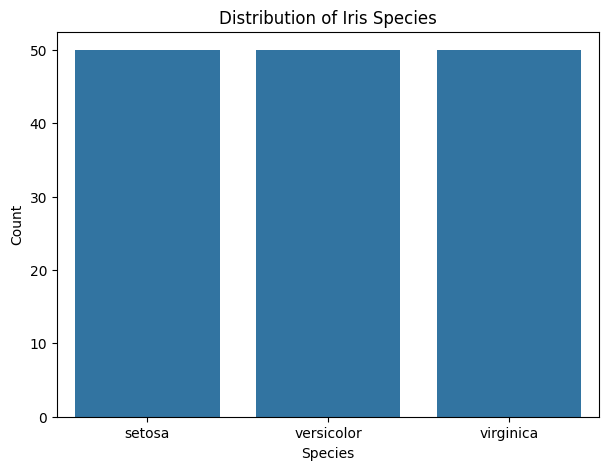

In [5]:
#Step 4: Data Visualization
#4.1 Visualize species distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

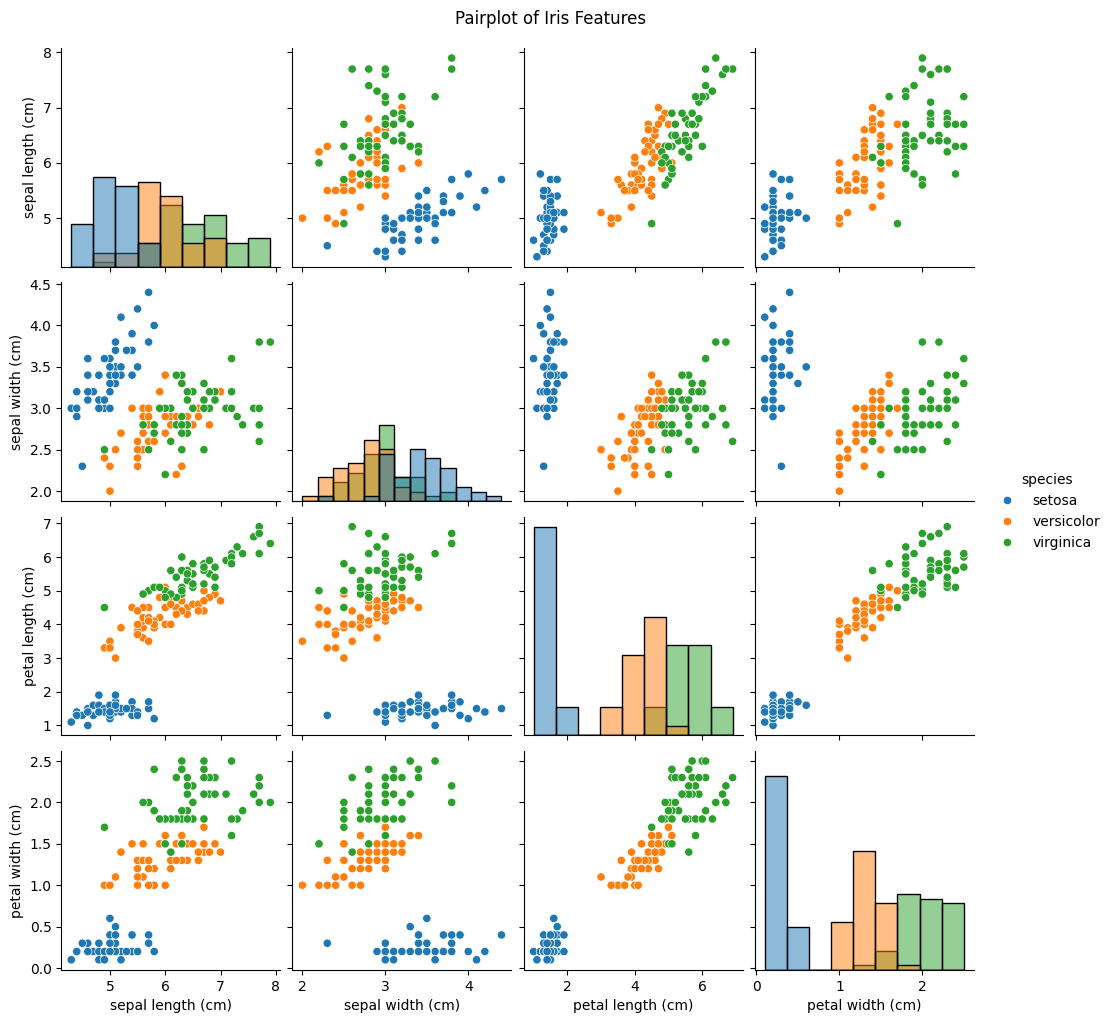

In [7]:
#4.2 Create a pairplot
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Features",
    y=1.02
)

plt.show()

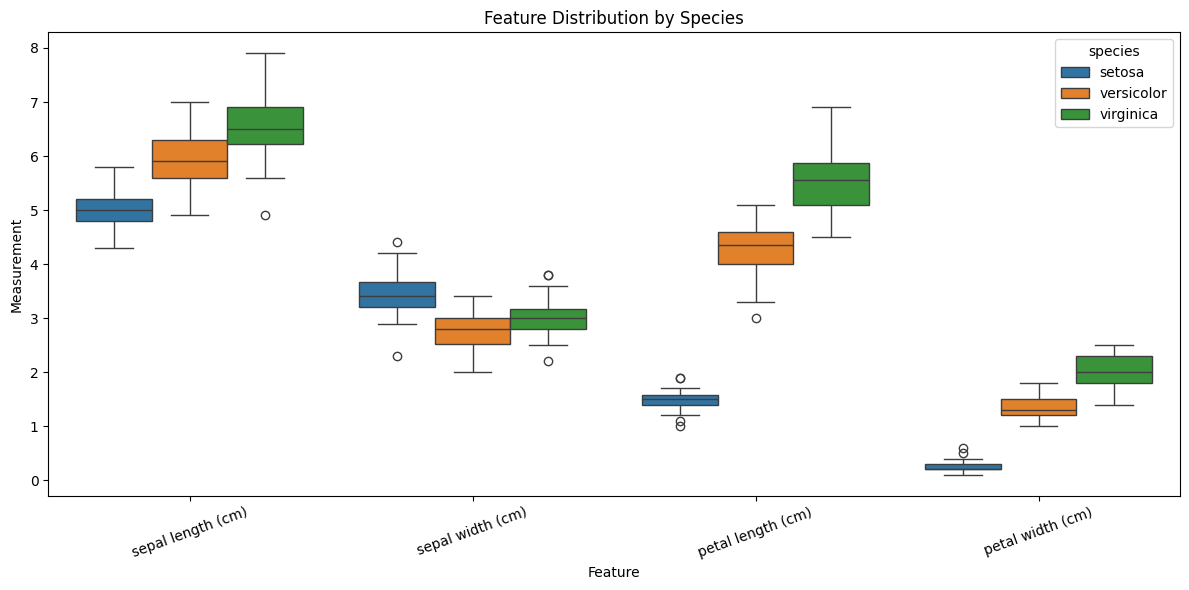

In [8]:
#4.3 Create boxplots for all features
# Convert the DataFrame into long format
df_melted = df.melt(
    id_vars="species",
    var_name="Feature",
    value_name="Measurement"
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_melted,
    x="Feature",
    y="Measurement",
    hue="species"
)

plt.title("Feature Distribution by Species")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

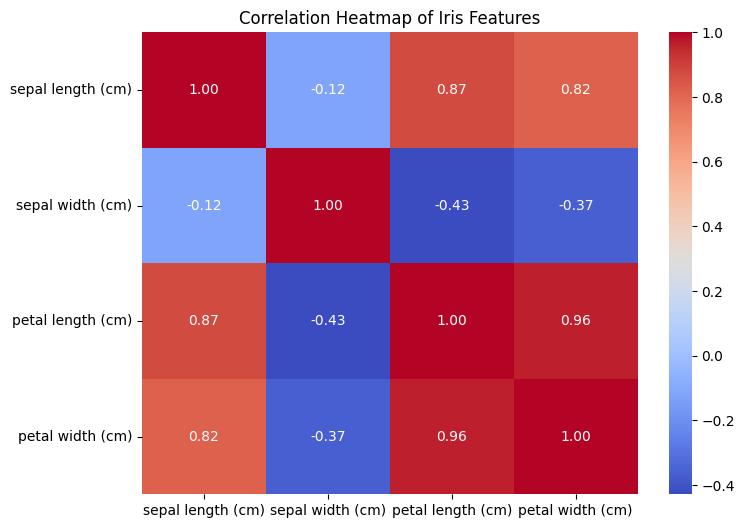

In [9]:
#4.4 Create a correlation heatmap
plt.figure(figsize=(8, 6))

correlation = df[iris.feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")

plt.show()

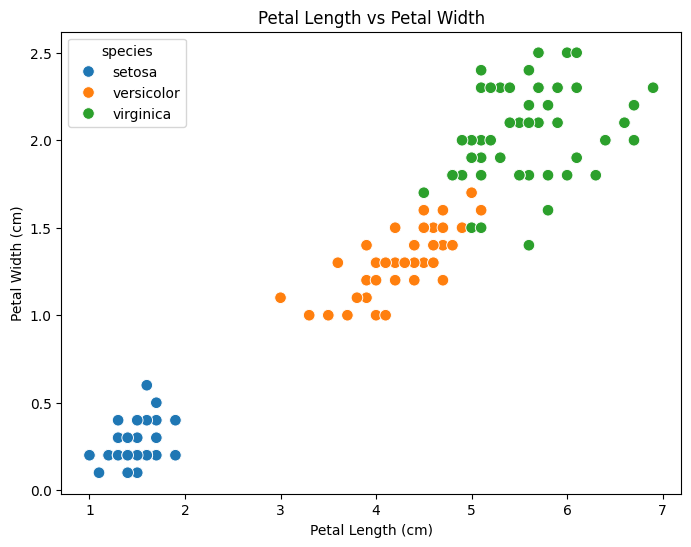

In [10]:
#Step 5: Feature Selection Discussion
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=70
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()


In [11]:
#Step 6: Split the Dataset
# Separate input features and target
X = df[iris.feature_names]
y = df["species"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)


In [12]:
#Step 7: Train the Machine Learning Models
# Define the classification models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "K-Nearest Neighbours": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

# Train the models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
K-Nearest Neighbours trained successfully!



Model: Logistic Regression
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



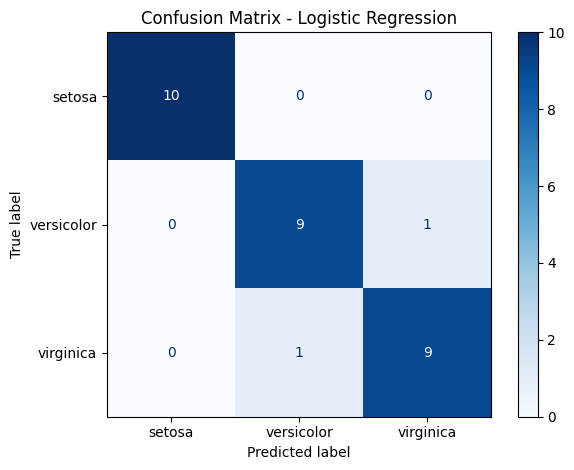


Model: K-Nearest Neighbours
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



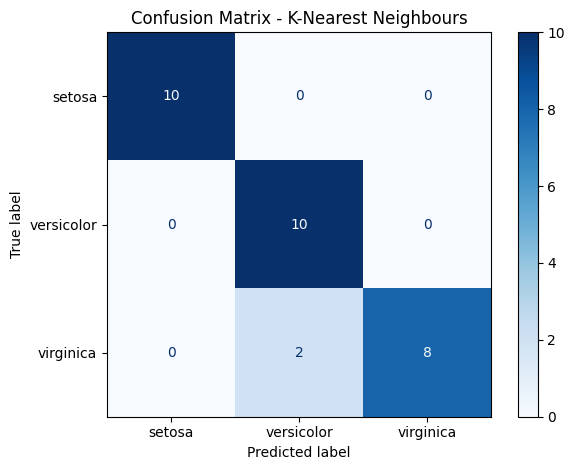

In [13]:
#Step 8: Evaluate the Models
# Store evaluation results
results = {}

for name, model in models.items():

    # Predict the test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate classification report
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    # Store results
    results[name] = {
        "Accuracy": accuracy,
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1-Score": report["macro avg"]["f1-score"]
    }

    print("\n" + "=" * 45)
    print("Model:", name)
    print("=" * 45)

    print(f"Accuracy: {accuracy:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    # Plot confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=iris.target_names,
        display_labels=iris.target_names,
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [15]:
#Step 9: Compare Model Performance
# Convert the results into a DataFrame
comparison_df = pd.DataFrame(results).T

# Display comparison
print("Model Performance Comparison:")
display(comparison_df.round(4))

Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.9333,0.9333,0.9333,0.9333
K-Nearest Neighbours,0.9333,0.9444,0.9333,0.9327


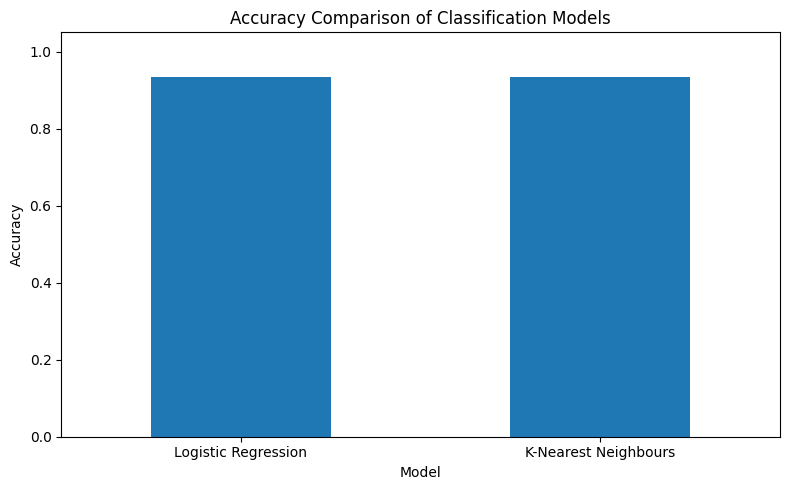

In [16]:
#Visualize the accuracy comparison
plt.figure(figsize=(8, 5))

comparison_df["Accuracy"].plot(
    kind="bar",
    rot=0
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

In [17]:
#Step 10: Identify the Best-Performing Model
# Sort models by accuracy and macro F1-score
comparison_df = comparison_df.sort_values(
    by=["Accuracy", "F1-Score"],
    ascending=False
)

# Select the best model
best_model_name = comparison_df.index[0]
best_model = models[best_model_name]

print("Best-Performing Model:", best_model_name)

print(
    "Best Model Accuracy:",
    f"{comparison_df.iloc[0]['Accuracy']:.2%}"
)

print(
    "Best Model F1-Score:",
    f"{comparison_df.iloc[0]['F1-Score']:.4f}"
)

Best-Performing Model: Logistic Regression
Best Model Accuracy: 93.33%
Best Model F1-Score: 0.9333


In [18]:
#Step 11: Predict the Species of a New Flower
# Example flower measurements:
# Sepal length, Sepal width, Petal length, Petal width

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Predict the species
prediction = best_model.predict(new_flower)

print("Predicted Iris Species:", prediction[0])

Predicted Iris Species: setosa


In [19]:
#Step 12: Display the Final Results
print("=" * 45)
print("IRIS FLOWER CLASSIFICATION - FINAL RESULTS")
print("=" * 45)

print("\nDataset Information:")
print("Total Samples:", len(df))
print("Number of Features:", len(iris.feature_names))
print("Number of Species:", len(iris.target_names))

print("\nModels Evaluated:")
for model_name in models:
    print("-", model_name)

print("\nModel Comparison:")
display(comparison_df.round(4))

print("\nBest-Performing Model:", best_model_name)

print(
    "Test Accuracy:",
    f"{comparison_df.loc[best_model_name, 'Accuracy']:.2%}"
)

print("\nProject Completed Successfully!")

IRIS FLOWER CLASSIFICATION - FINAL RESULTS

Dataset Information:
Total Samples: 150
Number of Features: 4
Number of Species: 3

Models Evaluated:
- Logistic Regression
- K-Nearest Neighbours

Model Comparison:


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.9333,0.9333,0.9333,0.9333
K-Nearest Neighbours,0.9333,0.9444,0.9333,0.9327



Best-Performing Model: Logistic Regression
Test Accuracy: 93.33%

Project Completed Successfully!


In [ ]:
"""Conclusion
The project successfully classifies iris flowers using machine learning. Two models were compared, and the best-performing model was selected based on its evaluation results."""